# 09 - Ablation studies: CNN components, recurrent networks, attention and positions
IMDB dataset, binary classification (positive / negative)

In notebook 08 we compared the four architectures with one configuration each. Here we change one
component at a time to see what each one contributes. To keep the computation small (a laptop GPU),
every variant is trained with one seed (42), except the reference LSTM, which is trained with the
3 seeds because it was very unstable in notebook 08. The data and the training settings are the
same as in notebook 08.

* **CNN:** kernel size (1 word, 3 words, or 3-4-5 words), max vs mean pooling, and no dropout.
* **Length of the input (CNN):** 64, 256 or 512 words.
* **Recurrent networks:** in notebook 08 early stopping ended the training of the LSTM too early
  (patience 2). Here all the recurrent networks are trained with more patience (4 epochs, at most 15).
  With these settings we compare the LSTM with: the padding processed as real input, a GRU, a
  bidirectional LSTM, and an LSTM with an attention layer over all its outputs (RNN + attention).
* **Transformer:** without positional embeddings (pure self-attention, which does not see the order).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import accuracy_score

from utils import set_style, save, SEED, RES_DIR, PURPLE, PINK, ORANGE, LILAC, PLUM, ROSE, INK
from imdb_utils import *

set_style()
ref_runs = pd.read_csv(RES_DIR / "imdb_architectures_runs.csv")

## 1. Data

Same preparation as in notebook 08 (`prepare_imdb` repeats it), also with 64 and 512 words.

In [2]:
data = {n: prepare_imdb(n) for n in [64, 256, 512]}
V = data[256]["vocab_size"]
print("vocabulary", V)

vocabulary 20000


**Bidirectional LSTM without packing.** With `pack_padded_sequence` a bidirectional LSTM takes about
340 s per epoch on this computer. The backward direction is an LSTM that reads every review from its
last real word to the first one, so it can be replaced by a second LSTM that receives the review with
its real words in reverse order (and the padding still at the end), taking again the state of the last
real word. We check with random weights that it gives the same output as the packed version:

In [3]:
torch.manual_seed(0)
xb, lb = data[256]["val"][0][:64], data[256]["val"][1][:64]
packed = RNNClassifier(V, bidirectional=True, mode="pack").eval()
two_lstms = RNNClassifier(V, bidirectional=True, mode="gather").eval()
weights = {("rnn_back." + k[4:-len("_reverse")] if k.endswith("_reverse") else k): v
           for k, v in packed.state_dict().items()}
two_lstms.load_state_dict(weights)
with torch.no_grad():
    print("max |packed - two LSTMs| =", (packed(xb, lb) - two_lstms(xb, lb)).abs().max().item())

max |packed - two LSTMs| = 6.705522537231445e-08


## 2. Variants

Every run is saved as soon as it finishes, so an interrupted execution continues where it stopped.

In [4]:
RNN_SET = dict(max_epochs=15, patience=4)
VARIANTS = [
    # (group, variant, data, model builder, training settings, seeds)
    ("CNN", "kernel 1 word", 256, lambda: TextCNN(V, kernel_sizes=(1,)), {}, [SEED]),
    ("CNN", "kernel 3 words", 256, lambda: TextCNN(V, kernel_sizes=(3,)), {}, [SEED]),
    ("CNN", "mean pooling", 256, lambda: TextCNN(V, pooling="mean"), {}, [SEED]),
    ("CNN", "no dropout", 256, lambda: TextCNN(V, dropout=0.0), {}, [SEED]),
    ("Length", "64 words", 64, lambda: TextCNN(V), {}, [SEED]),
    ("Length", "512 words", 512, lambda: TextCNN(V), {}, [SEED]),
    ("RNN", "reference: LSTM, patience 4", 256, lambda: RNNClassifier(V, mode="gather"), RNN_SET, [42, 43, 44]),
    ("RNN", "LSTM, padding processed as input", 256, lambda: RNNClassifier(V, mode="naive"), RNN_SET, [SEED]),
    ("RNN", "GRU", 256, lambda: RNNClassifier(V, cell="gru", mode="gather"), RNN_SET, [SEED]),
    ("RNN", "bidirectional LSTM", 256, lambda: RNNClassifier(V, bidirectional=True, mode="gather"), RNN_SET, [SEED]),
    ("RNN", "LSTM + attention", 256, lambda: LSTMAttention(V), RNN_SET, [SEED]),
    ("Transformer", "no positional embedding", 256, lambda: TransformerClassifier(V, positional=False), {}, [SEED]),
]

PARTIAL = RES_DIR / "imdb_ablation_partial.csv"
ATTN_WEIGHTS = RES_DIR / "imdb_lstm_attention.pt"
rows = pd.read_csv(PARTIAL).to_dict("records") if PARTIAL.exists() else []
done = {(r["variant"], r["seed"]) for r in rows}
for group, variant, key, build, settings, seeds in VARIANTS:
    d = data[key]
    for seed in seeds:
        if (variant, seed) in done:
            continue
        torch.manual_seed(seed)
        model = build()
        hist = train_text_model(model, d["train"], d["val"], seed=seed, **settings)
        X_te, L_te, y_te = d["test"]
        p = predict_proba(model, X_te, L_te)
        rows.append({"group": group, "variant": variant, "seed": seed, "parameters": count_parameters(model),
                     "best epoch": hist["best_epoch"], "seconds": hist["seconds"],
                     "seconds per epoch": hist["seconds"] / len(hist["val_loss"]),
                     "test accuracy": accuracy_score(y_te, p > 0.5)})
        pd.DataFrame(rows).to_csv(PARTIAL, index=False)
        if variant == "LSTM + attention":
            torch.save(model.state_dict(), ATTN_WEIGHTS)
        print(f"{group:12s} {variant:34s} seed {seed}: acc {rows[-1]['test accuracy']:.4f}, "
              f"best epoch {hist['best_epoch']}, {hist['seconds']:.0f} s")

runs = pd.DataFrame(rows)

CNN          kernel 1 word                      seed 42: acc 0.8536, best epoch 10, 49 s


CNN          kernel 3 words                     seed 42: acc 0.8504, best epoch 8, 52 s


CNN          mean pooling                       seed 42: acc 0.8686, best epoch 4, 105 s


CNN          no dropout                         seed 42: acc 0.8574, best epoch 4, 74 s


Length       64 words                           seed 42: acc 0.7724, best epoch 5, 32 s


Length       512 words                          seed 42: acc 0.8778, best epoch 7, 199 s


... (4 outputs left out)

RNN          GRU                                seed 42: acc 0.8593, best epoch 5, 373 s


RNN          bidirectional LSTM                 seed 42: acc 0.8409, best epoch 6, 219 s


RNN          LSTM + attention                   seed 42: acc 0.8747, best epoch 5, 143 s


Transformer  no positional embedding            seed 42: acc 0.8531, best epoch 3, 390 s


The references of the CNN and the Transformer are the runs of notebook 08 with seed 42 (the same seed
as the variants). The LSTM of notebook 08 (patience 2, 3 seeds) is added to the recurrent group.

In [5]:
def rows_from_08(group, variant, model, seeds):
    r = ref_runs[(ref_runs.model == model) & (ref_runs.seed.isin(seeds))]
    return [{"group": group, "variant": variant, "seed": x["seed"], "best epoch": x["best epoch"],
             "seconds": x["seconds"], "seconds per epoch": x["seconds per epoch"],
             "test accuracy": x["test accuracy"]} for _, x in r.iterrows()]

ref_rows = (rows_from_08("CNN", "reference: kernels 3-4-5, max pooling, dropout 0.5", "CNN", [SEED]) +
            rows_from_08("Length", "256 words (reference)", "CNN", [SEED]) +
            rows_from_08("Transformer", "reference: learned positions", "Transformer", [SEED]))
lstm_08 = rows_from_08("RNN", "LSTM, patience 2 (notebook 08)", "LSTM", [42, 43, 44])
runs = pd.concat([pd.DataFrame(ref_rows), runs, pd.DataFrame(lstm_08)], ignore_index=True)
runs.to_csv(RES_DIR / "imdb_ablation_runs.csv", index=False)

summary = runs.groupby(["group", "variant"], sort=False).agg(
    test_accuracy=("test accuracy", "mean"), test_accuracy_std=("test accuracy", "std"),
    seeds=("seed", "count"), best_epoch=("best epoch", "mean"),
    seconds_per_epoch=("seconds per epoch", "mean"))
ref_acc = summary.groupby(level=0, sort=False)["test_accuracy"].transform("first")
summary["difference with reference"] = summary["test_accuracy"] - ref_acc
summary.to_csv(RES_DIR / "imdb_ablation_summary.csv")
summary.round(4)

test_accuracy  \
group       variant                                                             
CNN         reference: kernels 3-4-5, max pooling, dropout 0.5         0.8657   
Length      256 words (reference)                                      0.8657   
Transformer reference: learned positions                               0.8305   
CNN         kernel 1 word                                              0.8536   
            kernel 3 words                                             0.8504   
            mean pooling                                               0.8686   
            no dropout                                                 0.8574   
Length      64 words                                                   0.7724   
            512 words                                                  0.8778   
RNN         reference: LSTM, patience 4                                0.8561   
            LSTM, padding processed as input                           0.8188   
            GRU                                                        0.8593   
            bidirectional LSTM                                         0.8409   
            LSTM + attention                                           0.8747   
Transformer no positional embedding                                    0.8531   
RNN         LSTM, patience 2 (notebook 08)                             0.8153   

                                                                test_accuracy_std  \
group       variant                                                                 
CNN         reference: kernels 3-4-5, max pooling, dropout 0.5                NaN   
Length      256 words (reference)                                             NaN   
Transformer reference: learned positions                                      NaN   
CNN         kernel 1 word                                                     NaN   
            kernel 3 words                                                    NaN   
            mean pooling                                                      NaN   
            no dropout                                                        NaN   
Length      64 words                                                          NaN   
            512 words                                                         NaN   
RNN         reference: LSTM, patience 4                                    0.0113   
            LSTM, padding processed as input                                  NaN   
            GRU                                                               NaN   
            bidirectional LSTM                                                NaN   
            LSTM + attention                                                  NaN   
Transformer no positional embedding                                           NaN   
RNN         LSTM, patience 2 (notebook 08)                                 0.0493   

                                                                seeds  \
group       variant                                                     
CNN         reference: kernels 3-4-5, max pooling, dropout 0.5      1   
Length      256 words (reference)                                   1   
Transformer reference: learned positions                            1   
CNN         kernel 1 word                                           1   
            kernel 3 words                                          1   
            mean pooling                                            1   
            no dropout                                              1   
Length      64 words                                                1   
            512 words                                               1   
RNN         reference: LSTM, patience 4                             3   
            LSTM, padding processed as input                        1   
            GRU                                                     1   
            bidirectional LSTM                      

In [6]:
print(runs[runs.variant.str.contains("LSTM, patience")][["variant", "seed", "best epoch", "test accuracy"]])

                           variant  seed  best epoch  test accuracy
9      reference: LSTM, patience 4    42           6        0.84888
10     reference: LSTM, patience 4    43           9        0.86920
11     reference: LSTM, patience 4    44           7        0.85036
17  LSTM, patience 2 (notebook 08)    42           4        0.81448
18  LSTM, patience 2 (notebook 08)    43           2        0.76644
19  LSTM, patience 2 (notebook 08)    44           9        0.86500


## 3. Results

Figure saved -> ../results/figures/imdb_ablations.png


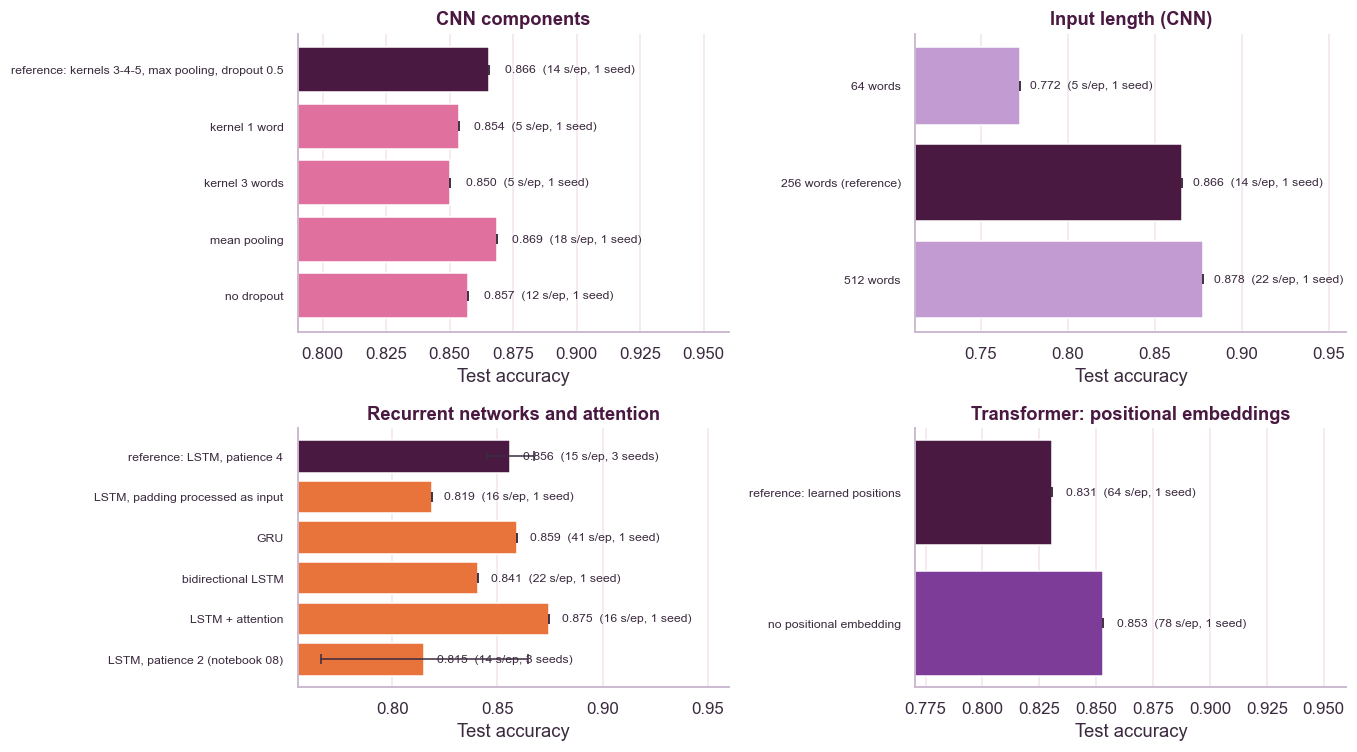

In [7]:
groups = ["CNN", "Length", "RNN", "Transformer"]
titles = {"CNN": "CNN components", "Length": "Input length (CNN)", "RNN": "Recurrent networks and attention",
          "Transformer": "Transformer: positional embeddings"}
cols = {"CNN": PINK, "Length": LILAC, "RNN": ORANGE, "Transformer": PURPLE}
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.0), gridspec_kw=dict(height_ratios=[1.15, 1]))
for ax, g in zip(axes.flat, groups):
    s = summary.loc[g]
    if g == "Length":
        s = s.loc[["64 words", "256 words (reference)", "512 words"]]
    names = list(s.index)
    colors = [PLUM if "reference" in n else cols[g] for n in names]
    ax.barh(names, s["test_accuracy"], xerr=s["test_accuracy_std"].fillna(0), color=colors,
            edgecolor="white", error_kw=dict(ecolor=INK, lw=1, capsize=3))
    for i, (v, t, k) in enumerate(zip(s["test_accuracy"], s["seconds_per_epoch"], s["seeds"])):
        ax.text(v + 0.006, i, f"{v:.3f}  ({t:.0f} s/ep, {k} seed{'s' if k > 1 else ''})", va="center", fontsize=8)
    ax.set_xlim(max(0.45, s["test_accuracy"].min() - 0.06), 0.96)
    ax.invert_yaxis()
    ax.set_xlabel("Test accuracy")
    ax.set_title(titles[g])
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "imdb_ablations.png")
plt.show()

## 4. What does the attention look at?

The LSTM + attention model gives one weight to every word of the review. We show the weights of the
12 words with the largest weight for two test reviews (one positive and one negative).

review 12513 (positive): I admire Deepa Mehta and this movie is a masterpiece. I'd recommend to buy this movie on DVD because it's a movie you might want to watch more often than just once. And trust me, you'd still find little meaningful details after watching it several times.<br /><br />The characters - except for the gr 

review 12 (negative): I first watched this movie back in the mid/late 80's, when I was a kid. We couldn't even get all the way through it. The dialog, the acting, everything about it was just beyond lame.<br /><br />Here are a few examples... imagine these spoken real dramatically, way over-acted: "Oreegon? You're going  

Figure saved -> ../results/figures/imdb_attention.png


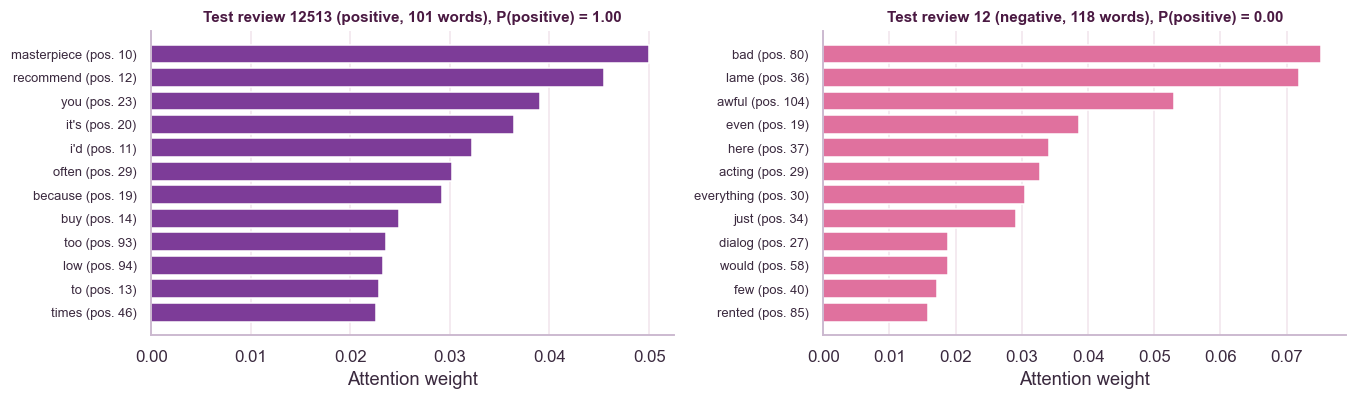

In [8]:
attn = LSTMAttention(V).to(DEVICE)
attn.load_state_dict(torch.load(ATTN_WEIGHTS, map_location=DEVICE))
attn.eval()
itos = {i: w for w, i in data[256]["vocab"].items()}
itos[UNK] = "<unk>"
X_te, L_te, y_te = data[256]["test"]
test_df = data[256]["test_df"]
short = np.where((L_te.numpy() > 60) & (L_te.numpy() < 120))[0]
examples = [short[y_te.numpy()[short] == 1][0], short[y_te.numpy()[short] == 0][0]]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
for ax, i in zip(axes, examples):
    with torch.no_grad():
        _, alpha = attn.attention(X_te[i:i + 1].to(DEVICE))
        prob = torch.sigmoid(attn(X_te[i:i + 1].to(DEVICE), L_te[i:i + 1])).item()
    a = alpha[0, :L_te[i]].cpu().numpy()
    top = np.argsort(-a)[:12][::-1]
    words = [itos[int(X_te[i, t])] for t in top]
    ax.barh(range(len(top)), a[top], color=PURPLE if y_te[i] == 1 else PINK)
    ax.set_yticks(range(len(top)), [f"{w} (pos. {t + 1})" for w, t in zip(words, top)], fontsize=8.5)
    label = "positive" if y_te[i] == 1 else "negative"
    ax.set_title(f"Test review {i} ({label}, {L_te[i]} words), P(positive) = {prob:.2f}", fontsize=10)
    ax.set_xlabel("Attention weight")
    ax.grid(axis="y", visible=False)
    print(f"review {i} ({label}):", test_df.text.iloc[i][:300], "\n")
fig.tight_layout()
save(fig, "imdb_attention.png")
plt.show()

## Summary

(One seed per variant, so I only consider differences larger than about 0.01 as real.)

- **CNN.** Combining kernels of 3, 4 and 5 words matters (0.866): with only kernels of 1 word (0.854) or of 3 words (0.850) the accuracy goes down. Kernels of 3 words alone are not better than kernels of 1 word, so the gain comes from the combination of widths (and the 3 times more filters). Mean or max pooling gives the same result, and dropout helps a little (+0.008).
- **Length.** The largest effect of the study: 64 words gives 0.772 and 512 words 0.878 (the best CNN), at 1.5 times the time per epoch.
- **Recurrent networks.** With patience 4 the LSTM is stable (0.856 ± 0.011 instead of 0.815 ± 0.049), so the problem of notebook 08 was early stopping. Taking the state after the padding costs 0.037. The GRU is as good as the LSTM (0.859) with fewer parameters, and the bidirectional LSTM is not better (0.841).
- **Attention.** The LSTM with attention is the best network with reviews of 256 words (0.875), and its weights go to the polarised words (masterpiece, recommend / bad, lame, awful).
- **Transformer.** Without positional embeddings it is better (0.853 vs 0.831), which agrees with the shuffling test of notebook 08: with 20,000 reviews it does not learn to use the positions.